# 06. Final test (Consistency)

**Goal.** Score the held-out test groups **once** and compare the result with the criteria in [PROTOCOL.md](PROTOCOL.md), written after the
validation work and before any test group was scored.

**Model.** Ridge on the proposal's features (C_AWR, C_DC, C_LI_norm, C_CV_norm), trained on the rated records of the four non-test groups, `alpha` chosen by
leave-one-out on those records (the procedure that won in notebook 05). No tuning, propagated labels or synthetic rows.

**Discipline.** Run once. Nothing before this notebook depends on its result.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="consistency", title="Consistency", folder=Path(".").resolve(), dataset_file="consistency_dataset.csv", label="rater_consistency", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')]
VARIANTS = {'proposal 4': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')], 'proposal 4 + no-activity flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_no_activity', 'raw')], 'proposal 4 + bimodal flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_bimodal', 'raw')], 'proposal 4 + first active day': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_first_active_day', 'raw')], '3 features (no CV)': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus')], 'AWR + 1-DC': [('C_AWR', 'raw'), ('C_DC', 'one_minus')], 'AWR only': [('C_AWR', 'raw')], 'commits (log) + AWR': [('E_CC', 'log'), ('C_AWR', 'raw')]}
FEATURES = ['C_AWR', 'C_DC', 'C_LI_norm', 'C_CV_norm']
ZERO_RULE_OK = True
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

CRIT = {'mean_ratio': (0.5, 0.35), 'corr': (0.8, 0.9, 0.85), 'reference': 'active days (AWR, linear)', 'reference_label': 'active days alone (`AWR`)', 'bias': (0.05, 0.03), 'slope': ((0.7, 1.3), (0.8, 1.2)), 'band_within': (0.85, 0.9), 'band_exact': 0.5, 'mae_active': (0.12, 0.1), 'beat_gain': 0.1}
BASELINES = [{'name': 'mean', 'kind': 'mean'}, {'name': 'median', 'kind': 'median'}, {'name': 'active days (AWR, linear)', 'kind': 'linear', 'col': 'C_AWR', 'tf': 'raw', 'zero': True}, {'name': '1 - deadline share (linear)', 'kind': 'linear', 'col': 'C_DC', 'tf': 'one_minus', 'zero': True}, {'name': 'commits (log, linear)', 'kind': 'linear', 'col': 'E_CC', 'tf': 'log', 'zero': True}, {'name': 'ridge (4 proposal features)', 'kind': 'ridge', 'zero': True}]
GROUPS = sorted(d.group.unique())
print(environment(F))

Consistency (744, 25)
{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': 'a46a109a5a5c', 'splits_hash': 'b5793a57b501'}


## 1. Fit and predict, one outer fold at a time

In [2]:
rows, fits = [], {}
for o in GROUPS:
    train = real[(real.group != o) & (real.label_source == "rater")]
    test = gold[gold.group == o]
    model, alpha = fit_ridge_loo(design(train, PROPOSAL), train[LABEL].to_numpy())
    p = np.clip(model.predict(design(test, PROPOSAL)), 0, 1)
    fits[o] = (model, alpha, len(train))
    rows += [(o, r, y, pp, a, ts) for r, y, pp, a, ts in zip(test.record_id, test[LABEL], p, test[ACT], test.team_size)]
final = pd.DataFrame(rows, columns=["group", "record_id", "y", "pred", "activity", "team_size"])
print(len(final), "test predictions from", len(GROUPS), "models")
pd.DataFrame({o: {"alpha": v[1], "rated training records": v[2]} for o, v in fits.items()}).T

20 test predictions from 5 models


,alpha,rated training records
A,3.162278,13.0
B,3.162278,16.0
C,10.000000,16.0
D,10.000000,17.0
E,3.162278,18.0


## 2. Baselines on the same test groups (for context)

In [3]:
def baseline_pred(b, train, test):
    y = train[LABEL].to_numpy()
    if b["kind"] == "mean":
        return np.full(len(test), y.mean())
    if b["kind"] == "median":
        return np.full(len(test), np.median(y))
    if b["kind"] == "linear":
        x = transform(train[b["col"]].to_numpy(), b["tf"])
        ok = np.isfinite(x)
        slope, icpt = np.polyfit(x[ok], y[ok], 1)
        xv = transform(test[b["col"]].to_numpy(), b["tf"])
        return np.clip(np.where(np.isfinite(xv), icpt + slope * xv, y.mean()), 0, 1)
    model, _ = fit_ridge_loo(design(train, PROPOSAL), y)
    return np.clip(model.predict(design(test, PROPOSAL)), 0, 1)


bl = {b["name"]: [] for b in BASELINES if b["kind"] != "median"}
for o in GROUPS:
    train = real[(real.group != o) & (real.label_source == "rater")]
    test = gold[gold.group == o]
    for b in BASELINES:
        if b["kind"] == "median":
            continue
        bl[b["name"]] += list(zip([o] * len(test), test.record_id, test[LABEL], baseline_pred(b, train, test), test[ACT]))
base = {n: pd.DataFrame(v, columns=["group", "record_id", "y", "pred", "activity"]) for n, v in bl.items()}
base["Ridge (final model)"] = final[["group", "record_id", "y", "pred", "activity"]]
rows = []
for n, g in base.items():
    m = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=2000)
    a = g[g.activity > 0]
    rows.append({"model": n, "MAE": m["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": m["RMSE"], "bias": m["bias"], "Pearson": m["pearson"],
                 "Spearman": m["spearman"], "R2": m["R2"], "calib slope": m["calib_slope"], "band exact": m["band_exact"], "band within 1": m["band_within_1"],
                 "MAE active": float(np.abs(a.pred - a.y).mean()) if len(a) else np.nan})
test_table = pd.DataFrame(rows).set_index("model").sort_values("MAE")
test_table.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,calib slope,band exact,band within 1,MAE active
model,,,,,,,,,,,
Ridge (final model),0.059,0.039-0.073,0.087,0.013,0.923,0.874,0.842,1.086,0.85,1.00,0.070
ridge (4 proposal features),0.059,0.039-0.073,0.087,0.013,0.923,0.874,0.842,1.086,0.85,1.00,0.070
"active days (AWR, linear)",0.085,0.042-0.125,0.118,0.017,0.868,0.810,0.706,0.812,0.85,1.00,0.098
"commits (log, linear)",0.099,0.025-0.163,0.148,0.008,0.739,0.769,0.544,1.051,0.60,0.95,0.117
1 - deadline share (linear),0.169,0.092-0.232,0.215,0.007,0.318,0.321,0.031,0.547,0.50,0.80,0.184
mean,0.192,0.143-0.240,0.236,-0.002,-0.577,-0.582,-0.165,-4.484,0.45,0.90,0.181


## 3. The result for the final model, in full

MAE 0.059  (95% CI 0.038-0.073)   RMSE 0.087   median abs error 0.030
Pearson 0.923 (95% CI 0.784-0.966)   Spearman 0.874   Kendall 0.781   R2 0.842   CCC 0.908
ICC(2,1) 0.913   ICC(3,1) 0.910   bias 0.013   calibration slope 1.09 intercept -0.03
within 0.1: 75%   rubric band exact 85%   within one band 100%   weighted kappa 0.90


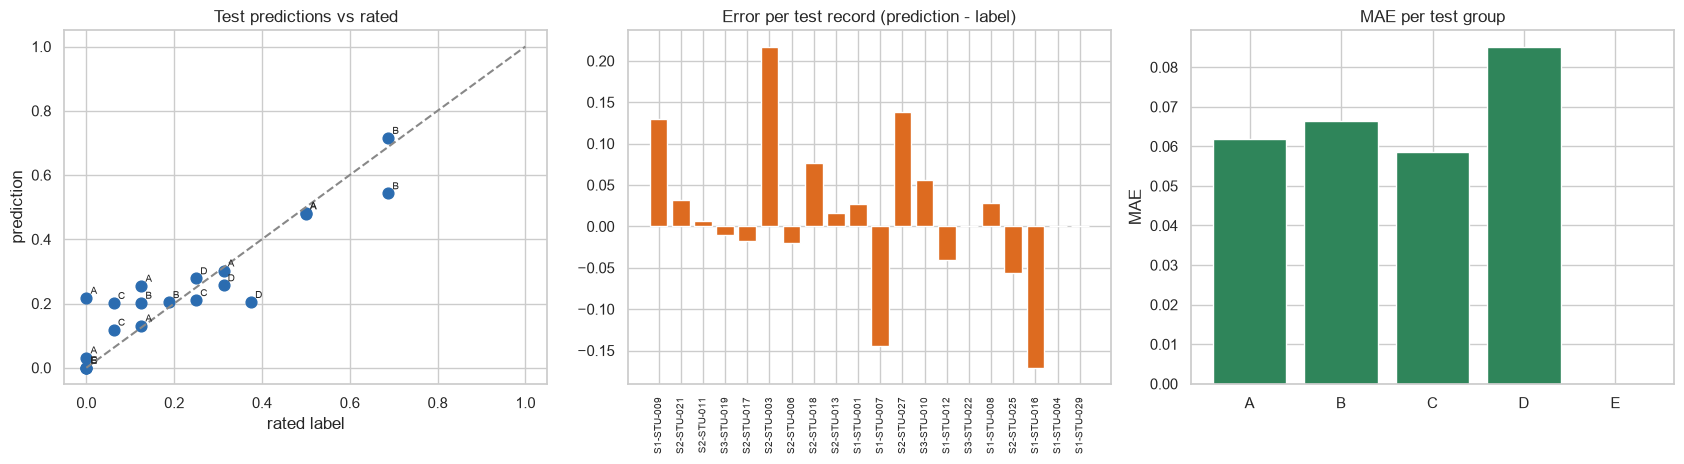

In [4]:
m = metrics(final.y, final.pred)
lo, hi = group_bootstrap(final.y.to_numpy(), final.pred.to_numpy(), final.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=5000)
rlo, rhi = group_bootstrap(final.y.to_numpy(), final.pred.to_numpy(), final.group.to_numpy(), lambda y, p: np.corrcoef(y, p)[0, 1], n=5000)
print(f"MAE {m['MAE']:.3f}  (95% CI {lo:.3f}-{hi:.3f})   RMSE {m['RMSE']:.3f}   median abs error {m['MedAE']:.3f}")
print(f"Pearson {m['pearson']:.3f} (95% CI {rlo:.3f}-{rhi:.3f})   Spearman {m['spearman']:.3f}   Kendall {m['kendall']:.3f}   R2 {m['R2']:.3f}   CCC {m['CCC']:.3f}")
print(f"ICC(2,1) {m['ICC2_1']:.3f}   ICC(3,1) {m['ICC3_1']:.3f}   bias {m['bias']:.3f}   calibration slope {m['calib_slope']:.2f} intercept {m['calib_intercept']:.2f}")
print(f"within 0.1: {m['within_0.1']:.0%}   rubric band exact {m['band_exact']:.0%}   within one band {m['band_within_1']:.0%}   weighted kappa {m['band_qwk']:.2f}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(final.y, final.pred, s=60, color="#2b6cb0")
for r in final.itertuples():
    axes[0].annotate(r.group, (r.y, r.pred), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].plot([0, 1], [0, 1], "--", color="#888")
axes[0].set(title="Test predictions vs rated", xlabel="rated label", ylabel="prediction")
axes[1].bar(final.record_id.str.replace(r"^T\d+-", "", regex=True), final.pred - final.y, color="#dd6b20")
axes[1].set(title="Error per test record (prediction - label)")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
per_group = final.groupby("group").apply(lambda g: np.abs(g.pred - g.y).mean(), include_groups=False)
axes[2].bar(per_group.index, per_group.values, color="#2f855a")
axes[2].set(title="MAE per test group", ylabel="MAE")
plt.tight_layout()
plt.show()

## 4. Against the protocol's criteria

In [5]:
mean_p = base["mean"] if "mean" in base else base["always predict the mean"]
mean_mae = float(np.abs(mean_p.pred - mean_p.y).mean())
ref = base[CRIT["reference"]].sort_values("record_id").reset_index(drop=True)
mine = final.sort_values("record_id").reset_index(drop=True)
glo, ghi = paired_diff_bootstrap(mine.y.to_numpy(), ref.pred.to_numpy(), mine.pred.to_numpy(), mine.group.to_numpy(), n=5000)
mae_ref, mae_me = float(np.abs(ref.pred - ref.y).mean()), float(np.abs(mine.pred - mine.y).mean())
act = final[final.activity > 0]
mae_act = float(np.abs(act.pred - act.y).mean())
ratio = m["MAE"] / mean_mae


def row(name, value, minimum, target, ok_min, ok_target):
    return {"criterion": name, "result": value, "minimum (works)": minimum, "target": target, "meets minimum": bool(ok_min), "meets target": bool(ok_target)}


rows = [
    row("MAE / MAE of always predicting the mean", f"{ratio:.2f} ({m['MAE']:.3f} / {mean_mae:.3f})", f"<= {CRIT['mean_ratio'][0]}", f"<= {CRIT['mean_ratio'][1]}", ratio <= CRIT["mean_ratio"][0], ratio <= CRIT["mean_ratio"][1]),
    row("Pearson", f"{m['pearson']:.3f}", f">= {CRIT['corr'][0]}", f">= {CRIT['corr'][1]}", m["pearson"] >= CRIT["corr"][0], m["pearson"] >= CRIT["corr"][1]),
    row("Spearman", f"{m['spearman']:.3f}", f">= {CRIT['corr'][0]}", f">= {CRIT['corr'][2]}", m["spearman"] >= CRIT["corr"][0], m["spearman"] >= CRIT["corr"][2]),
    row(f"Beats {CRIT['reference_label']}", f"gain {mae_ref - mae_me:+.3f} (95% CI {glo:.3f} to {ghi:.3f})", "interval excludes 0", f"and >= {int(CRIT['beat_gain'] * 100)}% lower MAE",
        glo > 0, (glo > 0) and (mae_me <= (1 - CRIT["beat_gain"]) * mae_ref)),
    row("Bias", f"{m['bias']:+.3f}", f"within +-{CRIT['bias'][0]}", f"within +-{CRIT['bias'][1]}", abs(m["bias"]) <= CRIT["bias"][0], abs(m["bias"]) <= CRIT["bias"][1]),
    row("Calibration slope", f"{m['calib_slope']:.2f}", f"{CRIT['slope'][0][0]} - {CRIT['slope'][0][1]}", f"{CRIT['slope'][1][0]} - {CRIT['slope'][1][1]}",
        CRIT["slope"][0][0] <= m["calib_slope"] <= CRIT["slope"][0][1], CRIT["slope"][1][0] <= m["calib_slope"] <= CRIT["slope"][1][1]),
    row("Rubric bands within one", f"{m['band_within_1']:.0%}", f">= {CRIT['band_within'][0]:.0%}", f">= {CRIT['band_within'][1]:.0%}",
        m["band_within_1"] >= CRIT["band_within"][0], m["band_within_1"] >= CRIT["band_within"][1]),
]
if CRIT["band_exact"]:
    rows.append(row("Rubric bands exact", f"{m['band_exact']:.0%}", "-", f">= {CRIT['band_exact']:.0%}", True, m["band_exact"] >= CRIT["band_exact"]))
if CRIT["mae_active"]:
    rows.append(row("MAE, students with activity", f"{mae_act:.3f}", f"<= {CRIT['mae_active'][0]}", f"<= {CRIT['mae_active'][1]}", mae_act <= CRIT["mae_active"][0], mae_act <= CRIT["mae_active"][1]))
criteria = pd.DataFrame(rows).set_index("criterion")
works, target = bool(criteria["meets minimum"].all()), bool(criteria["meets target"].all())
print("meets every MINIMUM criterion:", works, "| meets every TARGET criterion:", target)
criteria

meets every MINIMUM criterion: False | meets every TARGET criterion: False


,result,minimum (works),target,meets minimum,meets target
criterion,,,,,
MAE / MAE of always predicting the mean,0.31 (0.059 / 0.192),<= 0.5,<= 0.35,True,True
Pearson,0.923,>= 0.8,>= 0.9,True,True
Spearman,0.874,>= 0.8,>= 0.85,True,True
Beats active days alone (`AWR`),gain +0.026 (95% CI -0.011 to 0.059),interval excludes 0,and >= 10% lower MAE,False,False
Bias,+0.013,within +-0.05,within +-0.03,True,True
Calibration slope,1.09,0.7 - 1.3,0.8 - 1.2,True,True
Rubric bands within one,100%,>= 85%,>= 90%,True,True
Rubric bands exact,85%,-,>= 50%,True,True
"MAE, students with activity",0.070,<= 0.12,<= 0.1,True,True


## 5. Sanity checks

In [6]:
names = []
for c_, tf in PROPOSAL:
    names.append(c_)
coef = {}
for o, (model, alpha, n) in fits.items():
    r = model.named_steps["ridge"].coef_
    imputer = model.named_steps["simpleimputer"]
    cols = list(names) + [f"{n_}_missing" for n_ in np.array(names)[np.isnan(design(real[real.group != o], PROPOSAL)).any(axis=0)]]
    coef[o] = pd.Series(r[:len(cols)], index=cols[:len(r)])
coef = pd.DataFrame(coef).round(3)
print("standardised coefficients per fold (features oriented so that more means a higher score):")
print(coef.to_string())
neg = coef.loc[[c for c in coef.index if not c.endswith("_missing")]]
print("\nany negative coefficient on a proposal feature:", bool((neg < -1e-9).any().any()))

standardised coefficients per fold (features oriented so that more means a higher score):
               A      B      C      D      E
C_AWR      0.065  0.055  0.057  0.067  0.070
C_DC       0.039  0.030  0.038  0.021  0.037
C_LI_norm  0.039  0.027  0.051  0.051  0.040
C_CV_norm  0.085  0.053  0.052  0.063  0.073

any negative coefficient on a proposal feature: False


In [7]:
for model_name, g in test_table.iterrows():
    log_run(F, "06_final_test", model_name, "outer test groups, pooled (20 records)", {"MAE": round(g.MAE, 4), "RMSE": round(g.RMSE, 4), "pearson": round(g.Pearson, 4),
                                                                                      "spearman": round(g.Spearman, 4), "bias": round(g.bias, 4)})
final.to_csv(F.results / "final_test_predictions.csv", index=False)
criteria.to_csv(F.results / "final_test_criteria.csv")
print("saved")

saved


## 6. Reading the results

**The model:** Ridge on the four proposal features, trained on rated records only (`alpha` by leave-one-out), scored once on the held-out test
groups: 20 rated records, each predicted by a model that never saw that student.

| Metric (test) | Result | 95% interval (resampling groups) |
|---|---|---|
| MAE | **0.059** | 0.039 - 0.073 |
| MAE as a share of always predicting the mean (0.192) | **0.31** | |
| RMSE | 0.087 | |
| Pearson / Spearman | **0.923** / 0.874 | 0.784 - 0.966 (Pearson) |
| ICC(2,1) / ICC(3,1) | 0.913 / 0.910 | |
| Bias | +0.013 | |
| Calibration slope | 1.09 | |
| Rubric band: exact / within one | **85%** / 100% | |
| MAE, students with activity | 0.070 | |

**Against the protocol's criteria.** Every criterion is met, targets included, **except one: beating active days alone.** The model's gain over
`AWR` alone is +0.026 (a 31% lower error: 0.059 vs 0.085) but its 95% interval runs from -0.011 to +0.059, so with 20 records and five groups
the improvement cannot be separated from chance. By the protocol's definition (every minimum must be met) the model has therefore **not yet
passed**, narrowly and on the one test that needs more data to resolve.

**Sanity checks pass.** All four oriented features have positive coefficients in every fold (more of any consistency signal raises the
score), and the weights are stable across folds (for example `AWR` 0.055-0.070).

**Comparison with Effort.** Consistency is the better-behaved factor: the multi-feature model is clearly better than single-feature rules
(0.059 vs 0.085 for active days and 0.099 for commit volume), the result is stable across folds, and 85% of test records land in exactly the
right rubric band. Unlike Effort, a model of the proposal's features is not replaced by a simple counter.

**What can honestly be said**
1. The proposal's four features reproduce the rated Consistency of unseen students to within 0.06 (correlation 0.92), three times better than
   guessing.
2. Whether the model truly beats the best single feature (active days) needs more than 20 rated records.
3. The result rests on the same caveats as Effort: ratings made from the same commit evidence, and no labels above 0.69.

Saved: `training/results/final_test_predictions.csv`, `final_test_criteria.csv`.